# Capítulo 3 - Mecanismos de Atenção

Exploração interativa do Capítulo 3 (*Coding Attention Mechanisms*) do livro
*Build a Large Language Model (From Scratch)*, de Sebastian Raschka.

O código reutilizável está em `src/attention/` (Self-Attention, Causal
Attention, Multi-Head Attention); este notebook importa e experimenta com
ele, na mesma linha do notebook da Sprint 2
(`sprints/ch02/notebooks/InteligenciaArtificial_SistemasInteligentes.ipynb`).
A versão "oficial", testada com `pytest`, está em `sprints/ch03/tests/`; a
análise técnica completa está em `docs/sprint3_analise.md`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

import torch

from src.attention.self_attention import SelfAttention_v1, SelfAttention_v2, attention_scores_simples
from src.attention.causal_attention import CausalAttention
from src.attention.multi_head_attention import MultiHeadAttentionWrapper, MultiHeadAttention
from src.data.tokenizer import create_tokenizer
from src.data.dataloader import create_dataloader_v1
from src.data.embeddings import GPTInputEmbeddings

# Mesma frase de exemplo usada no livro: "Your journey starts with one step",
# ja convertida em embeddings (valores do proprio material do capitulo).
entradas = torch.tensor(
    [[0.43, 0.15, 0.89],   # Your
     [0.55, 0.87, 0.66],   # journey
     [0.57, 0.85, 0.64],   # starts
     [0.22, 0.58, 0.33],   # with
     [0.77, 0.25, 0.10],   # one
     [0.05, 0.80, 0.55]])  # step

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Shape das entradas de exemplo:", entradas.shape)

PROJECT_ROOT: /tmp/claude-0/-home-claude/df875057-9636-5de0-86ba-ce6ea22ae789/scratchpad/ch03
Shape das entradas de exemplo: torch.Size([6, 3])


## 3.3 Self-Attention sem pesos treináveis

O `Attention Score` entre dois tokens é o produto escalar de seus próprios
vetores de entrada; o softmax normaliza esses scores em `Attention Weights`
(cada linha soma 1); o `Context Vector` de cada token é a soma ponderada de
todos os vetores da sequência.

In [2]:
pesos_simples, contexto_simples = attention_scores_simples(entradas)

print("Pesos de atencao (cada linha soma 1):")
print(pesos_simples)
print("\nSoma da primeira linha:", pesos_simples[0].sum().item())

print("\nVetor de contexto de 'journey' (indice 1):", contexto_simples[1])
# Valor de referencia do livro para este exemplo:
esperado = torch.tensor([0.4419, 0.6515, 0.5683])
print("Valor de referencia do livro:              ", esperado)
print("Bate com o livro?", torch.allclose(contexto_simples[1], esperado, atol=1e-3))

Pesos de atencao (cada linha soma 1):


tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])

Soma da primeira linha: 1.0000001192092896

Vetor de contexto de 'journey' (indice 1): tensor([0.4419, 0.6515, 0.5683])
Valor de referencia do livro:               tensor([0.4419, 0.6515, 0.5683])
Bate com o livro? True


## 3.4 Self-Attention com pesos treináveis (Query, Key, Value)

Agora cada token é projetado em três papéis por matrizes treináveis:
`Query` (o que o token procura), `Key` (o que ele oferece) e `Value` (o
conteúdo que entra no vetor de contexto). Os scores (`Query @ Key.T`) são
divididos por `sqrt(d_out)` antes do softmax - a `Scaled Dot-Product
Attention` - para evitar que o softmax "sature" em dimensões altas.

In [3]:
torch.manual_seed(123)
self_attn_v1 = SelfAttention_v1(d_in=3, d_out=2)
saida_v1 = self_attn_v1(entradas)
print("SelfAttention_v1 (nn.Parameter):")
print(saida_v1)

torch.manual_seed(789)
self_attn_v2 = SelfAttention_v2(d_in=3, d_out=2)
saida_v2 = self_attn_v2(entradas)
print("\nSelfAttention_v2 (nn.Linear):")
print(saida_v2)

SelfAttention_v1 (nn.Parameter):
tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

SelfAttention_v2 (nn.Linear):
tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


In [4]:
# Por que escalonar por sqrt(d_out)? Simulamos scores brutos na magnitude
# tipica de uma dimensao alta (d_out=100) e comparamos o softmax com e sem
# a divisao por sqrt(d_out).
d_out = 100
torch.manual_seed(0)
scores_brutos = torch.randn(6, 6) * d_out**0.5

pesos_sem_escala = torch.softmax(scores_brutos, dim=-1)
pesos_com_escala = torch.softmax(scores_brutos / d_out**0.5, dim=-1)

print("Maior peso medio por linha, SEM escala:", pesos_sem_escala.max(dim=-1).values.mean().item())
print("Maior peso medio por linha, COM escala:", pesos_com_escala.max(dim=-1).values.mean().item())
print("-> sem escalar, o softmax fica bem mais concentrado (proximo de um degrau).")

Maior peso medio por linha, SEM escala: 0.7892632484436035
Maior peso medio por linha, COM escala: 0.40121224522590637
-> sem escalar, o softmax fica bem mais concentrado (proximo de um degrau).


## 3.5 Causal Attention (mascarada, em lote)

Para a tarefa de `Next-Word Prediction`, um token só pode "ver" ele mesmo e
os tokens anteriores - nunca o futuro. A máscara causal zera (via `-inf`
antes do softmax) tudo que está acima da diagonal principal da matriz de
scores. `CausalAttention` também processa um **lote** de sequências de uma
vez (`batch_size, num_tokens, d_in`), como o que sai do `DataLoader` +
`GPTInputEmbeddings` da Sprint 2, e aplica `Dropout` sobre os pesos.

In [5]:
lote = torch.stack([entradas])  # (1, 6, 3): um lote com uma sequencia

torch.manual_seed(123)
causal = CausalAttention(d_in=3, d_out=2, context_length=6, dropout=0.0)
saida_causal = causal(lote)
print("Shape da saida:", saida_causal.shape)

# Recalculamos os pesos internos so para visualizar a mascara em acao.
with torch.no_grad():
    q = causal.W_query(lote)
    k = causal.W_key(lote)
    scores = q @ k.transpose(1, 2)
    scores.masked_fill_(causal.mask.bool()[:6, :6], -torch.inf)
    pesos_causais = torch.softmax(scores / causal.d_out**0.5, dim=-1)[0]

print("\nMatriz de pesos (formato triangular inferior, por causa da mascara):")
print(pesos_causais.round(decimals=3))
print("\nSoma da parte 'futura' (acima da diagonal), deve ser 0:",
      torch.triu(pesos_causais, diagonal=1).sum().item())

Shape da saida: torch.Size([1, 6, 2])

Matriz de pesos (formato triangular inferior, por causa da mascara):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4830, 0.5170, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3410, 0.3400, 0.0000, 0.0000, 0.0000],
        [0.2440, 0.2550, 0.2540, 0.2470, 0.0000, 0.0000],
        [0.1990, 0.2060, 0.2060, 0.1930, 0.1950, 0.0000],
        [0.1620, 0.1710, 0.1710, 0.1650, 0.1620, 0.1680]])

Soma da parte 'futura' (acima da diagonal), deve ser 0: 0.0


## 3.6 Multi-Head Attention

Duas versões, ambas do livro: `MultiHeadAttentionWrapper` roda `num_heads`
`CausalAttention` independentes em um laço Python e concatena as saídas
(clara, mas ineficiente). `MultiHeadAttention` calcula a mesma coisa em uma
única passagem tensorial, dividindo `d_out` em `num_heads` fatias de
`head_dim = d_out / num_heads` - é a versão que a Sprint 4 vai reaproveitar
no Transformer Block.

In [6]:
torch.manual_seed(123)
mha_wrapper = MultiHeadAttentionWrapper(d_in=3, d_out=2, context_length=6, dropout=0.0, num_heads=2)
saida_wrapper = mha_wrapper(lote)
print("Wrapper (2 cabecas de d_out=2 cada): shape =", saida_wrapper.shape, "-> 2*2 = 4 colunas")

torch.manual_seed(123)
mha = MultiHeadAttention(d_in=3, d_out=4, context_length=6, dropout=0.0, num_heads=2)
saida_mha = mha(lote)
print("Eficiente (d_out=4 total, 2 cabecas de head_dim=2): shape =", saida_mha.shape)
print("Numero de parametros:", sum(p.numel() for p in mha.parameters()))

Wrapper (2 cabecas de d_out=2 cada): shape = torch.Size([1, 6, 4]) -> 2*2 = 4 colunas
Eficiente (d_out=4 total, 2 cabecas de head_dim=2): shape = torch.Size([1, 6, 4])
Numero de parametros: 56


## 3.7 Experimentação

Os mesmos 7 experimentos de `experiments/fluxo_sprint3.py`, rodados aqui de
forma interativa (célula por experimento, para facilitar reexecutar com
outros valores).

### Experimento 1 - Diferentes dimensões de embedding (`d_out`)

In [7]:
for d_out in (2, 8, 32, 128):
    torch.manual_seed(123)
    camada = SelfAttention_v2(d_in=3, d_out=d_out)
    saida = camada(entradas)
    n_params = sum(p.numel() for p in camada.parameters())
    print(f"d_out={d_out:>4} | shape da saida={tuple(saida.shape)} | parametros={n_params}")

d_out=   2 | shape da saida=(6, 2) | parametros=18
d_out=   8 | shape da saida=(6, 8) | parametros=72


d_out=  32 | shape da saida=(6, 32) | parametros=288
d_out= 128 | shape da saida=(6, 128) | parametros=1152


### Experimento 2 - Diferentes números de heads (`d_out` total fixo)

In [8]:
lote_8d = torch.stack([torch.rand(6, 8)])

for num_heads in (1, 2, 3, 4, 6):
    torch.manual_seed(123)
    camada = MultiHeadAttention(d_in=8, d_out=24, context_length=6, num_heads=num_heads)
    saida = camada(lote_8d)
    print(f"num_heads={num_heads} | head_dim={camada.head_dim} | shape={tuple(saida.shape)} | parametros={sum(p.numel() for p in camada.parameters())}")

num_heads=1 | head_dim=24 | shape=(1, 6, 24) | parametros=1176
num_heads=2 | head_dim=12 | shape=(1, 6, 24) | parametros=1176
num_heads=3 | head_dim=8 | shape=(1, 6, 24) | parametros=1176
num_heads=4 | head_dim=6 | shape=(1, 6, 24) | parametros=1176
num_heads=6 | head_dim=4 | shape=(1, 6, 24) | parametros=1176


### Experimento 3 - Diferentes dimensões de head (`num_heads` fixo)

In [9]:
for head_dim in (2, 4, 8, 16):
    d_out = head_dim * 4
    torch.manual_seed(123)
    camada = MultiHeadAttention(d_in=8, d_out=d_out, context_length=6, num_heads=4)
    saida = camada(lote_8d)
    print(f"head_dim={head_dim:>3} | d_out total={d_out:>3} | shape={tuple(saida.shape)} | parametros={sum(p.numel() for p in camada.parameters())}")

head_dim=  2 | d_out total=  8 | shape=(1, 6, 8) | parametros=264
head_dim=  4 | d_out total= 16 | shape=(1, 6, 16) | parametros=656
head_dim=  8 | d_out total= 32 | shape=(1, 6, 32) | parametros=1824
head_dim= 16 | d_out total= 64 | shape=(1, 6, 64) | parametros=5696


### Experimento 4 - Self-Attention (1 cabeça) vs Multi-Head Attention

In [10]:
torch.manual_seed(123)
uma_cabeca = MultiHeadAttention(d_in=8, d_out=8, context_length=6, num_heads=1)
saida_1 = uma_cabeca(lote_8d)

torch.manual_seed(123)
quatro_cabecas = MultiHeadAttention(d_in=8, d_out=8, context_length=6, num_heads=4)
saida_4 = quatro_cabecas(lote_8d)

print(f"1 cabeca  (head_dim={uma_cabeca.head_dim}) | parametros={sum(p.numel() for p in uma_cabeca.parameters())} | shape={tuple(saida_1.shape)}")
print(f"4 cabecas (head_dim={quatro_cabecas.head_dim}) | parametros={sum(p.numel() for p in quatro_cabecas.parameters())} | shape={tuple(saida_4.shape)}")
print("-> mesmos parametros e shape final; a diferenca e conceitual (1 padrao de relacao vs 4 em paralelo).")

1 cabeca  (head_dim=8) | parametros=264 | shape=(1, 6, 8)
4 cabecas (head_dim=2) | parametros=264 | shape=(1, 6, 8)
-> mesmos parametros e shape final; a diferenca e conceitual (1 padrao de relacao vs 4 em paralelo).


### Experimento 5 - Comportamento da máscara causal (com x sem)

In [11]:
torch.manual_seed(123)
camada_mascara = CausalAttention(d_in=8, d_out=4, context_length=6, dropout=0.0)
with torch.no_grad():
    q = camada_mascara.W_query(lote_8d)
    k = camada_mascara.W_key(lote_8d)
    scores = q @ k.transpose(1, 2)

    pesos_sem_mascara = torch.softmax(scores / camada_mascara.d_out**0.5, dim=-1)[0]

    scores_mascarados = scores.clone()
    scores_mascarados.masked_fill_(camada_mascara.mask.bool()[:6, :6], -torch.inf)
    pesos_com_mascara = torch.softmax(scores_mascarados / camada_mascara.d_out**0.5, dim=-1)[0]

print("Peso do token 0 para os tokens 1..5, SEM mascara (soma):", pesos_sem_mascara[0, 1:].sum().item())
print("Peso do token 0 para os tokens 1..5, COM mascara (soma):", pesos_com_mascara[0, 1:].sum().item())

Peso do token 0 para os tokens 1..5, SEM mascara (soma): 0.8398258686065674
Peso do token 0 para os tokens 1..5, COM mascara (soma): 0.0


### Experimento 6 - Diferentes sequências de entrada (corpus do projeto)

Usa três frases do domínio de Segurança da Informação do projeto (o mesmo
tema do corpus CompTIA Security+ da Sprint 2) para rodar o pipeline
completo: tokenizador → `DataLoader` → `GPTInputEmbeddings` → `MultiHeadAttention`.

In [12]:
frases_seguranca = [
    "Um firewall bloqueia ataques que tentam explorar vulnerabilidades da rede.",
    "Um firewall bem configurado impede acessos nao autorizados a rede interna.",
    "Ataques de phishing tentam enganar usuarios para roubar credenciais de acesso.",
]
texto_completo = " ".join(frases_seguranca)
tokenizer = create_tokenizer(texto_completo)

for frase in frases_seguranca:
    print(f"'{frase[:55]}...' | tokens={len(tokenizer.encode(frase))}")

max_length = 6
dataloader = create_dataloader_v1(
    texto_completo, tokenizer, batch_size=2, max_length=max_length,
    stride=max_length, shuffle=False, drop_last=True,
)
inputs, _ = next(iter(dataloader))

torch.manual_seed(123)
embedding_dim = 16
emb = GPTInputEmbeddings(vocab_size=len(tokenizer.str_to_int), context_length=max_length, embedding_dim=embedding_dim)
x = emb(inputs)

torch.manual_seed(123)
mha_seguranca = MultiHeadAttention(d_in=embedding_dim, d_out=embedding_dim, context_length=max_length, num_heads=4)
saida_seguranca = mha_seguranca(x)

print("\nShape dos embeddings de entrada:", tuple(x.shape))
print("Shape da saida (multi-head attention):", tuple(saida_seguranca.shape))

'Um firewall bloqueia ataques que tentam explorar vulner...' | tokens=11
'Um firewall bem configurado impede acessos nao autoriza...' | tokens=12
'Ataques de phishing tentam enganar usuarios para roubar...' | tokens=12

Shape dos embeddings de entrada: (2, 6, 16)
Shape da saida (multi-head attention): (2, 6, 16)


## 3.8 Experimento 7 - Visualização das matrizes de atenção

Heatmap dos pesos de atenção de cada cabeça, para a primeira sequência do
lote acima ("Um firewall bloqueia ataques que tentam"). O formato
triangular inferior é a máscara causal em ação; a primeira posição só
"enxerga" a si mesma.

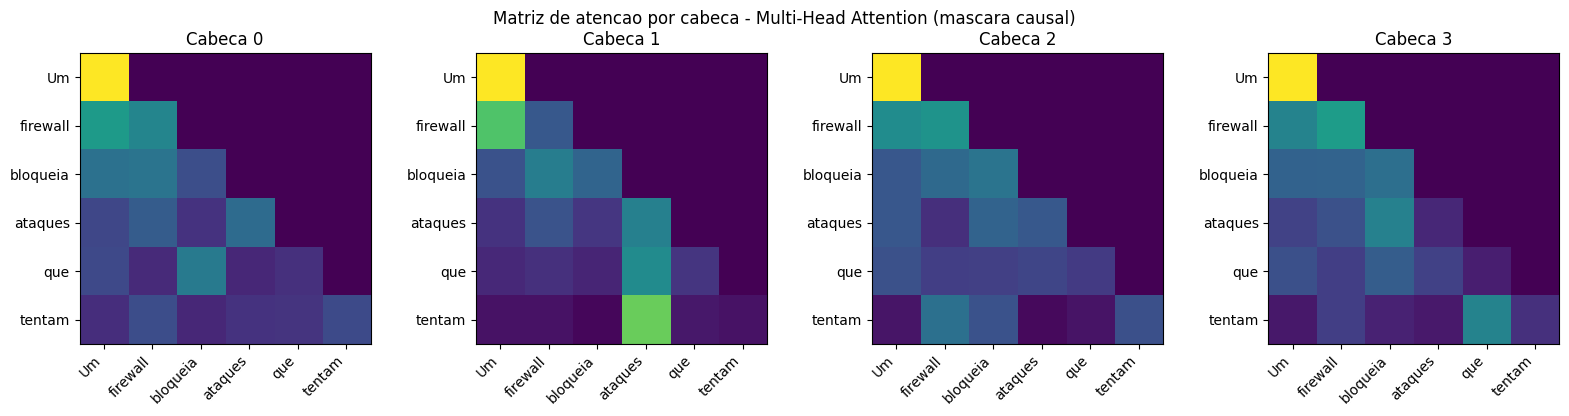

In [13]:
import matplotlib.pyplot as plt

with torch.no_grad():
    b, n, _ = x.shape
    q = mha_seguranca.W_query(x).view(b, n, mha_seguranca.num_heads, mha_seguranca.head_dim).transpose(1, 2)
    k = mha_seguranca.W_key(x).view(b, n, mha_seguranca.num_heads, mha_seguranca.head_dim).transpose(1, 2)
    scores = q @ k.transpose(2, 3)
    scores.masked_fill_(mha_seguranca.mask.bool()[:n, :n], -torch.inf)
    pesos_atencao = torch.softmax(scores / mha_seguranca.head_dim**0.5, dim=-1)

tokens = [tokenizer.int_to_str[i] for i in inputs[0].tolist()]
num_heads = pesos_atencao.shape[1]

fig, eixos = plt.subplots(1, num_heads, figsize=(4 * num_heads, 4))
for cabeca, eixo in enumerate(eixos):
    matriz = pesos_atencao[0, cabeca].numpy()
    eixo.imshow(matriz, cmap="viridis", vmin=0, vmax=1)
    eixo.set_title(f"Cabeca {cabeca}")
    eixo.set_xticks(range(len(tokens))); eixo.set_xticklabels(tokens, rotation=45, ha="right")
    eixo.set_yticks(range(len(tokens))); eixo.set_yticklabels(tokens)

fig.suptitle("Matriz de atencao por cabeca - Multi-Head Attention (mascara causal)")
fig.tight_layout()
plt.show()

## 3.9 Análise dos resultados

A interpretação técnica completa de cada experimento acima - por que
escalonar, por que a máscara causal é necessária, a relação entre `d_out`,
`num_heads` e `head_dim`, e o que a Sprint 4 vai reaproveitar daqui - está
em [`docs/sprint3_analise.md`](../docs/sprint3_analise.md).